# Previsão de séries temporais com PatchTSMixer



Tive que desistalar pois havia conflito por causa das versões

In [ ]:
!pip uninstall -y transformers accelerate granite-tsfm torch torchvision

Found existing installation: transformers 4.57.6
Uninstalling transformers-4.57.6:
  Successfully uninstalled transformers-4.57.6
Found existing installation: accelerate 1.12.0
Uninstalling accelerate-1.12.0:
  Successfully uninstalled accelerate-1.12.0
Found existing installation: torch 2.9.0+cu126
Uninstalling torch-2.9.0+cu126:
  Successfully uninstalled torch-2.9.0+cu126
Found existing installation: torchvision 0.24.0+cu126
Uninstalling torchvision-0.24.0+cu126:
  Successfully uninstalled torchvision-0.24.0+cu126


Como não sabia utilizar o modelo, copiei as configurações do tutorial fornecido e fiz apenas algumas variações para os meus testes, porém não utilizei early stopping presente no notebook.

In [ ]:
!pip install "granite-tsfm[notebooks] @ git+https://github.com/ibm-granite/granite-tsfm.git"

  Cloning https://github.com/ibm-granite/granite-tsfm.git to /tmp/pip-install-wyw5iq4f/granite-tsfm_ee945434025f40f8965db4d79e93cd1d
  Running command git clone --filter=blob:none --quiet https://github.com/ibm-granite/granite-tsfm.git /tmp/pip-install-wyw5iq4f/granite-tsfm_ee945434025f40f8965db4d79e93cd1d
  Resolved https://github.com/ibm-granite/granite-tsfm.git to commit 9f4d052058997741f23c9c9a6da7c422e5ce2d8a
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 143.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 887.9/887.9 MB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 594.3/594.3 MB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 138.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.

In [ ]:
!pip install sktime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.3/36.3 MB 46.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 151.5/151.5 kB 16.7 MB/s eta 0:00:00


Importando bibliotecas

In [ ]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from urllib.request import urlretrieve
from transformers import(
    EarlyStoppingCallback,
    PatchTSMixerConfig,
    PatchTSMixerForPrediction,
    Trainer,
    TrainingArguments,
)

from sktime.datasets import load_forecastingdata
from tsfm_public.toolkit.dataset import ForecastDFDataset
from datasets import load_dataset
from tsfm_public.toolkit.time_series_preprocessor import TimeSeriesPreprocessor
from tsfm_public.toolkit.util import select_by_index

Lista para guardar os resultados

In [ ]:
resultados = []

Função auxiliar para formatar datasets

In [ ]:
def formataDataSet(dataset):
  serie = dataset[dataset['series_name'] == 'T1'].copy()
  # separando linhas
  dfFinal = serie.explode('series_value')
  dfFinal['series_value'] = dfFinal['series_value'].astype(float)

  # criando timestamp
  start_date = pd.to_datetime(serie['start_timestamp'].iloc[0])
  dfFinal['timestamp'] = pd.date_range(start=start_date, periods=len(dfFinal), freq='h')

  # limpar o DataFrame para o modelo
  dfFinal = dfFinal[['timestamp', 'series_value']].rename(columns={'series_value': 'T1'})

  print(f'Série T1 com {len(dfFinal)} horas,\nComeçando em {start_date}')
  print(dfFinal.head())
  return dfFinal


Escolha datasets de áreas variadas, sendo todos com frequência horária e verificando a diferença do mse no início do teste e no final, todos foram testados em períodos similares de tempo.

Datasets usados (utilizei somente 4 e não 5) : M4, Eletricity, NN5, San Francisco Traffic

Formatando primeiro DataSet:

Usei a primeira coluna que constitui uma das séries temporais utilizada na M4, esse em específico é constituído de várias séries temporais (cada uma é uma coluna).

In [ ]:
dataset,metadata = load_forecastingdata("m4_hourly_dataset")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

m4_hourly_dataset.tsf: 0.00B [00:00, ?B/s]

In [ ]:
dataset.head()

,series_name,start_timestamp,series_value
0,T1,2015-07-01 12:00:00,"[605.0, 586.0, 586.0, 559.0, 511.0, 443.0, 422..."
1,T2,2015-07-01 12:00:00,"[3124.0, 2990.0, 2862.0, 2809.0, 2544.0, 2201...."
2,T3,2015-07-01 12:00:00,"[1828.0, 1806.0, 1897.0, 1750.0, 1679.0, 1620...."
3,T4,2015-07-01 12:00:00,"[6454.0, 6324.0, 6075.0, 5949.0, 5858.0, 5579...."
4,T5,2015-07-01 12:00:00,"[4263.0, 4297.0, 4236.0, 4080.0, 3883.0, 3672...."


In [ ]:
# definindo dataset
dfFinal = formataDataSet(dataset)
# o periodo de
context_length = 512
# horizonte de previsão
fh = 48

# período de treinamento 0- 600
y_treino = dfFinal.iloc[0:600]
# avalia o erro logo após o treino.
y_teste = dfFinal.iloc[0:650]
# última hora 748, período de contexto 748 - 560 = 188.
y_testedistante = dfFinal.iloc[188:748]

# normalização
tsp = TimeSeriesPreprocessor(
    timestamp_column='timestamp',
    target_columns=['T1'],
    scaling=True,
)
# arrumar a escala
tsp.train(y_treino)

train_aug = tsp.preprocess(y_treino)
near_aug = tsp.preprocess(y_teste)
far_aug = tsp.preprocess(y_testedistante)

Série T1 com 748 horas,
Começando em 2015-07-01 12:00:00
            timestamp     T1
0 2015-07-01 12:00:00  605.0
0 2015-07-01 13:00:00  586.0
0 2015-07-01 14:00:00  586.0
0 2015-07-01 15:00:00  559.0
0 2015-07-01 16:00:00  511.0


Configurando o Modelo

In [ ]:
# modelo escolhido PatchTSMixer
config = PatchTSMixerConfig(
    context_length=context_length,
    prediction_length=fh,
    num_input_channels=1,
    patch_length=8,
    d_model=16,
    num_layers=3,
    dropout=0.2,
    mode="common_channel",
    scaling="std",
)
model = PatchTSMixerForPrediction(config=config)

# configurando treinamento
train_args = TrainingArguments(
    output_dir="./checkpoint_univariado",
    num_train_epochs=30,
    per_device_train_batch_size=32,
    learning_rate=1e-3,
    save_strategy="no",
    logging_steps=10,
    report_to="none"
)

# separando datasets prontos do Toolkit
train_dataset = ForecastDFDataset(train_aug, target_columns=['T1'], context_length=context_length, prediction_length=fh)
trainer = Trainer(model=model, args=train_args, train_dataset=train_dataset)
trainer.train()

Step,Training Loss
10,0.261700
20,0.078700
30,0.056400
40,0.046300
50,0.042700
60,0.039000


TrainOutput(global_step=60, training_loss=0.0874809334675471, metrics={'train_runtime': 3.0548, 'train_samples_per_second': 402.65, 'train_steps_per_second': 19.641, 'total_flos': 437466562560.0, 'train_loss': 0.0874809334675471, 'epoch': 30.0})

In [ ]:
# organizando datasets de teste
dsTeste = ForecastDFDataset(near_aug, target_columns=['T1'], context_length=context_length, prediction_length=fh)
dsTesteMaisDistante = ForecastDFDataset(far_aug, target_columns=['T1'], context_length=context_length, prediction_length=fh)

# avaliando o erro (já da o mse)
metrics_near = trainer.evaluate(dsTeste)
metrics_far = trainer.evaluate(dsTesteMaisDistante)

# eval_loss nesse modelo é o mse
mse_base = metrics_near['eval_loss']
mse_degrad = metrics_far['eval_loss']

print(f'MSE INICIAL: {mse_base:.5f}')
print(f'MSE FINAL: {mse_degrad:.5f}')

if mse_degrad > mse_base:
    # Cálculo do aumento percentual do erro
    diff = ((mse_degrad - mse_base) / mse_base) * 100
    print(f'O erro aumentou {diff:.2f}% (Houve Degradação Temporal)')

elif mse_degrad < mse_base:
    # Caso raro onde o modelo performa melhor no futuro
    diff = ((mse_base - mse_degrad) / mse_base) * 100
    print(f'O erro diminuiu {diff:.2f}% (Não houve degradação)')
else:
    print('O modelo manteve a precisão no período.')

    # salvando resultados para comparações futuras
resultado_atual = {
    'Dataset': 'M4',
    'Horizonte': f'48h',
    'Contexto': context_length,
    'MSE_Inicial': mse_base,
    'MSE_Final': mse_degrad,
    'Degradacao_%': diff if mse_degrad > mse_base else 0
}

resultados.append(resultado_atual)

MSE INICIAL: 0.04805
MSE FINAL: 0.03569
O erro diminuiu 25.72% (Não houve degradação)


Aumetando o horizonte de previsão (96 horas)

In [ ]:
fh = 96
context_length = 512
ponto_de_corte = 620

y_treino = dfFinal.iloc[0:ponto_de_corte]
# 620 (fim do treino) + 96 (previsão) = 716
y_teste = dfFinal.iloc[0:716]
# última hora 748 - 608 = 140.
y_testedistante = dfFinal.iloc[140:748]

# normalização
tsp = TimeSeriesPreprocessor(
    timestamp_column='timestamp',
    target_columns=['T1'],
    scaling=True,
)
# arrumar a escala
tsp.train(y_treino)


train_aug = tsp.preprocess(y_treino)
near_aug = tsp.preprocess(y_teste)
far_aug = tsp.preprocess(y_testedistante)

In [ ]:
# modelo escolhido PatchTSMixer
config = PatchTSMixerConfig(
    context_length=context_length,
    prediction_length=fh,
    num_input_channels=1,
    patch_length=8,
    d_model=16,
    num_layers=3,
    dropout=0.2,
    mode="common_channel",
    scaling="std",
)
model = PatchTSMixerForPrediction(config=config)

# configurando treinamento
train_args = TrainingArguments(
    output_dir="./checkpoint_univariado",
    num_train_epochs=30,
    per_device_train_batch_size=32,
    learning_rate=1e-3,
    save_strategy="no",
    logging_steps=10,
    report_to="none"
)

# separando datasets prontos do Toolkit
train_dataset = ForecastDFDataset(train_aug, target_columns=['T1'], context_length=context_length, prediction_length=fh)
trainer = Trainer(model=model, args=train_args, train_dataset=train_dataset)
trainer.train()

Step,Training Loss
10,0.270700
20,0.061400
30,0.045300


TrainOutput(global_step=30, training_loss=0.12579296628634135, metrics={'train_runtime': 0.8396, 'train_samples_per_second': 464.529, 'train_steps_per_second': 35.733, 'total_flos': 197654446080.0, 'train_loss': 0.12579296628634135, 'epoch': 30.0})

In [ ]:
# organizando datasets de teste
dsTeste = ForecastDFDataset(near_aug, target_columns=['T1'], context_length=context_length, prediction_length=fh)
dsTesteMaisDistante = ForecastDFDataset(far_aug, target_columns=['T1'], context_length=context_length, prediction_length=fh)

# avaliando o erro (já da o mse)
metrics_near = trainer.evaluate(dsTeste)
metrics_far = trainer.evaluate(dsTesteMaisDistante)

# eval_loss nesse modelo é o mse
mse_base = metrics_near['eval_loss']
mse_degrad = metrics_far['eval_loss']

print(f'MSE INICIAL: {mse_base:.5f}')
print(f'MSE FINAL: {mse_degrad:.5f}')

if mse_degrad > mse_base:
    # Cálculo do aumento percentual do erro
    diff = ((mse_degrad - mse_base) / mse_base) * 100
    print(f'O erro aumentou {diff:.2f}% (Houve Degradação Temporal)')

elif mse_degrad < mse_base:
    # Caso raro onde o modelo performa melhor no futuro
    diff = ((mse_base - mse_degrad) / mse_base) * 100
    print(f'O erro diminuiu {diff:.2f}% (Não houve degradação)')
else:
    print('O modelo manteve a precisão no período.')

    # salvando resultados para comparações futuras
resultado_atual = {
    'Dataset': 'M4',
    'Horizonte': f'96',
    'Contexto': context_length,
    'MSE_Inicial': mse_base,
    'MSE_Final': mse_degrad,
    'Degradacao_%': diff if mse_degrad > mse_base else 0
}

resultados.append(resultado_atual)

MSE INICIAL: 0.15904
MSE FINAL: 0.23141
O erro aumentou 45.51% (Houve Degradação Temporal)


Resultados

In [ ]:
dfResultado = pd.DataFrame(resultados)
print('Tabela comparativa:')
display(dfResultado)

Tabela comparativa:


,Dataset,Horizonte,Contexto,MSE_Inicial,MSE_Final,Degradacao_%
0,M4,48h,512,0.048053,0.035692,0.000000
1,M4,96,512,0.159036,0.231413,45.509497


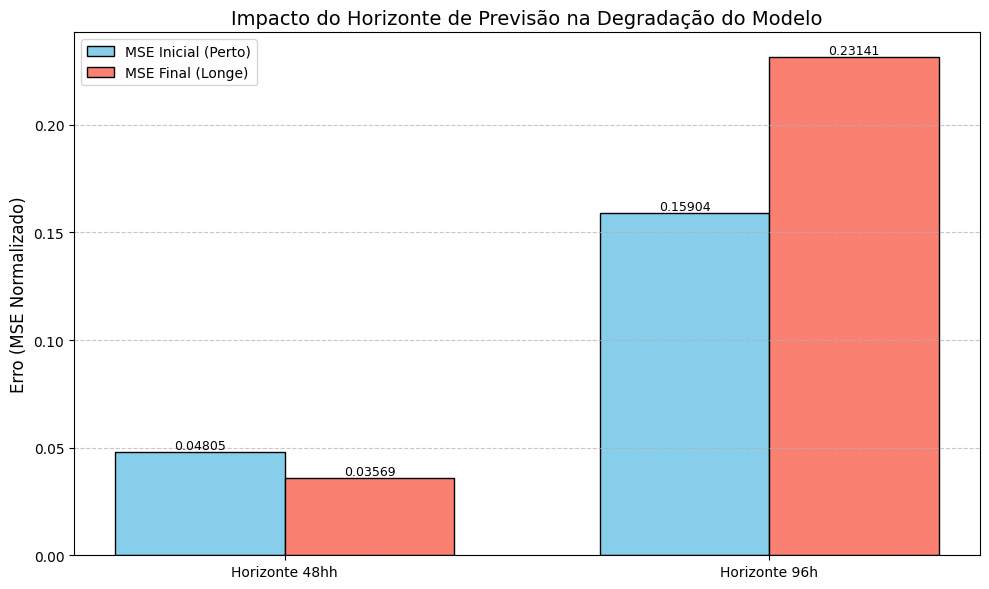

In [ ]:
horizontes = dfResultado['Horizonte'].values
mse_inicial = dfResultado['MSE_Inicial'].values
mse_final = dfResultado['MSE_Final'].values

x = np.arange(len(horizontes))  # Localização dos grupos no eixo X
width = 0.35  # Largura das barras

plt.figure(figsize=(10, 6))
plt.bar(x - width/2, mse_inicial, width, label='MSE Inicial (Perto)', color='skyblue', edgecolor='black')
plt.bar(x + width/2, mse_final, width, label='MSE Final (Longe)', color='salmon', edgecolor='black')

# customização do Gráfico
plt.ylabel('Erro (MSE Normalizado)', fontsize=12)
plt.title('Impacto do Horizonte de Previsão na Degradação do Modelo', fontsize=14)
plt.xticks(x, [f'Horizonte {h}h' for h in horizontes])
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# adicionar os valores numéricos em cima das barras
for i in range(len(horizontes)):
    plt.text(i - width/2, mse_inicial[i], f'{mse_inicial[i]:.5f}', ha='center', va='bottom', fontsize=9)
    plt.text(i + width/2, mse_final[i], f'{mse_final[i]:.5f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

**Formatando Segundo DataSet:**


Consumo de eletricidade

In [ ]:
dataset,metadata = load_forecastingdata(name="electricity_hourly_dataset")

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

electricity_hourly_dataset/electricity_h(…):   0%|          | 0.00/35.9M [00:00<?, ?B/s]

In [ ]:
dfFinal = formataDataSet(dataset)

Série T1 com 26304 horas,
Começando em 2012-01-01 00:00:01
            timestamp    T1
0 2012-01-01 00:00:01  14.0
0 2012-01-01 01:00:01  18.0
0 2012-01-01 02:00:01  21.0
0 2012-01-01 03:00:01  20.0
0 2012-01-01 04:00:01  22.0


In [ ]:
# definindo dataset
dfFinal = formataDataSet(dataset)
# o periodo de
context_length = 512
# horizonte de previsão
fh = 48

# período de treinamento 0 - 20000
y_treino = dfFinal.iloc[0:20000]

# avalia o erro logo após o treino.
y_teste = dfFinal.iloc[0:20050]

# última hora 26304, período de contexto 26304 - 560 = 25744.
y_testedistante = dfFinal.iloc[25744:26304]

# normalização
tsp = TimeSeriesPreprocessor(
    timestamp_column='timestamp',
    target_columns=['T1'],
    scaling=True,
)
# arrumar a escala
tsp.train(y_treino)


train_aug = tsp.preprocess(y_treino)
near_aug = tsp.preprocess(y_teste)
far_aug = tsp.preprocess(y_testedistante)

Série T1 com 26304 horas,
Começando em 2012-01-01 00:00:01
            timestamp    T1
0 2012-01-01 00:00:01  14.0
0 2012-01-01 01:00:01  18.0
0 2012-01-01 02:00:01  21.0
0 2012-01-01 03:00:01  20.0
0 2012-01-01 04:00:01  22.0


Configurando o Modelo e o Treinamento

In [ ]:
# modelo escolhido PatchTSMixer
config = PatchTSMixerConfig(
    context_length=context_length,
    prediction_length=fh,
    num_input_channels=1,
    patch_length=8,
    d_model=16,
    num_layers=3,
    dropout=0.2,
    mode="common_channel",
    scaling="std",
)
model = PatchTSMixerForPrediction(config=config)

# configurando treinemnto
train_args = TrainingArguments(
    output_dir="./checkpoint_univariado",
    num_train_epochs=30,
    per_device_train_batch_size=32,
    learning_rate=1e-3,
    save_strategy="no",
    logging_steps=10,
    report_to="none"
)

# separando datasets prontos do Toolkit
train_dataset = ForecastDFDataset(train_aug, target_columns=['T1'], context_length=context_length, prediction_length=fh)
trainer = Trainer(model=model, args=train_args, train_dataset=train_dataset)
trainer.train()


Step,Training Loss
10,0.580800
20,0.471600
30,0.431000
40,0.424200
50,0.470900
60,0.407200
70,0.363800
80,0.439200
90,0.425900
100,0.438600


TrainOutput(global_step=18240, training_loss=0.22813416158682423, metrics={'train_runtime': 372.5732, 'train_samples_per_second': 1565.41, 'train_steps_per_second': 48.957, 'total_flos': 207433840066560.0, 'train_loss': 0.22813416158682423, 'epoch': 30.0})

Avaliando Resultados

In [ ]:
# organizando datasets de teste
dsTeste = ForecastDFDataset(near_aug, target_columns=['T1'], context_length=context_length, prediction_length=fh)
dsTesteMaisDistante = ForecastDFDataset(far_aug, target_columns=['T1'], context_length=context_length, prediction_length=fh)

# avaliando o erro (já da o mse)
metrics_near = trainer.evaluate(dsTeste)
metrics_far = trainer.evaluate(dsTesteMaisDistante)

# eval_loss nesse modelo é o mse
mse_base = metrics_near['eval_loss']
mse_degrad = metrics_far['eval_loss']

print(f'MSE INICIAL: {mse_base:.5f}')
print(f'MSE FINAL: {mse_degrad:.5f}')

if mse_degrad > mse_base:
    # Cálculo do aumento percentual do erro
    diff = ((mse_degrad - mse_base) / mse_base) * 100
    print(f'O erro aumentou {diff:.2f}% (Houve Degradação Temporal)')

elif mse_degrad < mse_base:
    # Caso raro onde o modelo performa melhor no futuro
    diff = ((mse_base - mse_degrad) / mse_base) * 100
    print(f'O erro diminuiu {diff:.2f}% (Não houve degradação)')
else:
    print('O modelo manteve a precisão no período.')

# salvando resultados para comparações futuras
resultado_atual = {
    'Dataset': 'Eletricidade',
    'Horizonte': f'48h',
    'Contexto': context_length,
    'MSE_Inicial': mse_base,
    'MSE_Final': mse_degrad,
    'Degradacao_%': diff if mse_degrad > mse_base else 0
}

resultados.append(resultado_atual)

MSE INICIAL: 0.16893
MSE FINAL: 0.00696
O erro diminuiu 95.88% (Não houve degradação)


Aumentando o horizonte de prevosão 96 horas

In [ ]:
fh = 96
context_length = 512
ponto_de_corte = 620

# período de treinamento 0 - 20000
y_treino = dfFinal.iloc[0:20000]
# 20000 (fim do treino) + 96 (previsão) = 20096
y_teste = dfFinal.iloc[0:20096]
# última hora 26304 - 608 = 25696.
y_testedistante = dfFinal.iloc[25696:26304]

# normalização
tsp = TimeSeriesPreprocessor(
    timestamp_column='timestamp',
    target_columns=['T1'],
    scaling=True,
)
# arrumar a escala
tsp.train(y_treino)


train_aug = tsp.preprocess(y_treino)
near_aug = tsp.preprocess(y_teste)
far_aug = tsp.preprocess(y_testedistante)

In [ ]:
# modelo escolhido PatchTSMixer
config = PatchTSMixerConfig(
    context_length=context_length,
    prediction_length=fh,
    num_input_channels=1,
    patch_length=8,
    d_model=16,
    num_layers=3,
    dropout=0.2,
    mode="common_channel",
    scaling="std",
)
model = PatchTSMixerForPrediction(config=config)

# configurando treinemnto
train_args = TrainingArguments(
    output_dir="./checkpoint_univariado",
    num_train_epochs=30,
    per_device_train_batch_size=32,
    learning_rate=1e-3,
    save_strategy="no",
    logging_steps=10,
    report_to="none"
)

# separando datasets prontos do Toolkit
train_dataset = ForecastDFDataset(train_aug, target_columns=['T1'], context_length=context_length, prediction_length=fh)
trainer = Trainer(model=model, args=train_args, train_dataset=train_dataset)
trainer.train()

Step,Training Loss
10,0.613000
20,0.546900
30,0.513200
40,0.517600
50,0.552000
60,0.536500
70,0.455500
80,0.437100
90,0.489500
100,0.450200


TrainOutput(global_step=18210, training_loss=0.2585228672857667, metrics={'train_runtime': 359.9742, 'train_samples_per_second': 1616.199, 'train_steps_per_second': 50.587, 'total_flos': 294854820986880.0, 'train_loss': 0.2585228672857667, 'epoch': 30.0})

In [ ]:
# organizando datasets de teste
dsTeste = ForecastDFDataset(near_aug, target_columns=['T1'], context_length=context_length, prediction_length=fh)
dsTesteMaisDistante = ForecastDFDataset(far_aug, target_columns=['T1'], context_length=context_length, prediction_length=fh)

# avaliando o erro (já da o mse)
metrics_near = trainer.evaluate(dsTeste)
metrics_far = trainer.evaluate(dsTesteMaisDistante)

# eval_loss nesse modelo é o mse
mse_base = metrics_near['eval_loss']
mse_degrad = metrics_far['eval_loss']

print(f'MSE INICIAL: {mse_base:.5f}')
print(f'MSE FINAL: {mse_degrad:.5f}')

if mse_degrad > mse_base:
    # Cálculo do aumento percentual do erro
    diff = ((mse_degrad - mse_base) / mse_base) * 100
    print(f'O erro aumentou {diff:.2f}% (Houve Degradação Temporal)')

elif mse_degrad < mse_base:
    # Caso raro onde o modelo performa melhor no futuro
    diff = ((mse_base - mse_degrad) / mse_base) * 100
    print(f'O erro diminuiu {diff:.2f}% (Não houve degradação)')
else:
    print('O modelo manteve a precisão no período.')

# salvando resultados para comparações futuras
resultado_atual = {
    'Dataset': 'Eletricidade',
    'Horizonte': f'96h',
    'Contexto': context_length,
    'MSE_Inicial': mse_base,
    'MSE_Final': mse_degrad,
    'Degradacao_%': diff if mse_degrad > mse_base else 0
}
resultados.append(resultado_atual)

MSE INICIAL: 0.19322
MSE FINAL: 0.04275
O erro diminuiu 77.88% (Não houve degradação)


Resultados

In [ ]:
dfResultado = pd.DataFrame(resultados)
print('Tabela comparativa:')
display(dfResultado.iloc[2:4])

Tabela comparativa:


,Dataset,Horizonte,Contexto,MSE_Inicial,MSE_Final,Degradacao_%
2,Eletricidade,48h,512,0.168931,0.006963,0.0
3,Eletricidade,96h,512,0.193221,0.042746,0.0


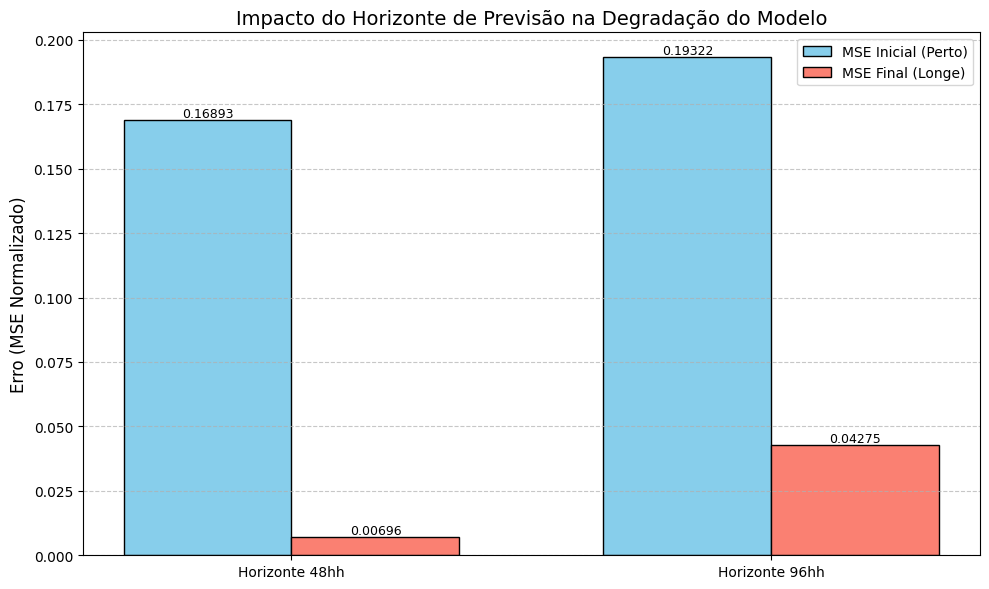

In [ ]:
horizontes = dfResultado.iloc[2:4]['Horizonte'].values
mse_inicial = dfResultado.iloc[2:4]['MSE_Inicial'].values
mse_final = dfResultado.iloc[2:4]['MSE_Final'].values

x = np.arange(len(horizontes))
width = 0.35

plt.figure(figsize=(10, 6))
plt.bar(x - width/2, mse_inicial, width, label='MSE Inicial (Perto)', color='skyblue', edgecolor='black')
plt.bar(x + width/2, mse_final, width, label='MSE Final (Longe)', color='salmon', edgecolor='black')

# customização do Gráfico
plt.ylabel('Erro (MSE Normalizado)', fontsize=12)
plt.title('Impacto do Horizonte de Previsão na Degradação do Modelo', fontsize=14)
plt.xticks(x, [f'Horizonte {h}h' for h in horizontes])
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# adicionando os valores numéricos em cima das barras
for i in range(len(horizontes)):
    plt.text(i - width/2, mse_inicial[i], f'{mse_inicial[i]:.5f}', ha='center', va='bottom', fontsize=9)
    plt.text(i + width/2, mse_final[i], f'{mse_final[i]:.5f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

**Terceiro DataSet:**

Taxa de ocupação das estradas em São Francisco

In [ ]:
dataset,metadata = load_forecastingdata(name='traffic_hourly_dataset')

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

traffic_hourly_dataset/traffic_hourly_da(…):   0%|          | 0.00/103M [00:00<?, ?B/s]

In [ ]:
dfFinal = formataDataSet(dataset)

Série T1 com 17544 horas,
Começando em 2015-01-01 00:00:01
            timestamp      T1
0 2015-01-01 00:00:01  0.0048
0 2015-01-01 01:00:01  0.0072
0 2015-01-01 02:00:01  0.0040
0 2015-01-01 03:00:01  0.0039
0 2015-01-01 04:00:01  0.0042


In [ ]:
context_length = 512
# horizonte de previsão
fh = 48

# período de treinamento 0- 600
y_treino = dfFinal.iloc[0:600]
# teste logo após o treino
y_teste = dfFinal.iloc[0:650]
# última hora
y_testedistante = dfFinal.iloc[16984:17544]


# normalização
tsp = TimeSeriesPreprocessor(
    timestamp_column='timestamp',
    target_columns=['T1'],
    scaling=True,
)
# arrumar a escala
tsp.train(y_treino)

train_aug = tsp.preprocess(y_treino)
near_aug = tsp.preprocess(y_teste)
far_aug = tsp.preprocess(y_testedistante)

In [ ]:
# modelo escolhido PatchTSMixer
config = PatchTSMixerConfig(
    context_length=context_length,
    prediction_length=fh,
    num_input_channels=1,
    patch_length=8,
    d_model=16,
    num_layers=3,
    dropout=0.2,
    mode="common_channel",
    scaling="std",
)
model = PatchTSMixerForPrediction(config=config)

# configurando treinemnto
train_args = TrainingArguments(
    output_dir="./checkpoint_univariado",
    num_train_epochs=30,
    per_device_train_batch_size=32,
    learning_rate=1e-3,
    save_strategy="no",
    logging_steps=10,
    report_to="none"
)

# separando datasets prontos do Toolkit
train_dataset = ForecastDFDataset(train_aug, target_columns=['T1'], context_length=context_length, prediction_length=fh)
trainer = Trainer(model=model, args=train_args, train_dataset=train_dataset)
trainer.train()


Step,Training Loss
10,0.143600
20,0.061100
30,0.043100
40,0.037200
50,0.031100
60,0.029800


TrainOutput(global_step=60, training_loss=0.05763618846734365, metrics={'train_runtime': 0.9025, 'train_samples_per_second': 1362.824, 'train_steps_per_second': 66.479, 'total_flos': 437466562560.0, 'train_loss': 0.05763618846734365, 'epoch': 30.0})

In [ ]:
# organizando datasets de teste
dsTeste = ForecastDFDataset(near_aug, target_columns=['T1'], context_length=context_length, prediction_length=fh)
dsTesteMaisDistante = ForecastDFDataset(far_aug, target_columns=['T1'], context_length=context_length, prediction_length=fh)

# avaliando o erro (já da o mse)
metrics_near = trainer.evaluate(dsTeste)
metrics_far = trainer.evaluate(dsTesteMaisDistante)

# eval_loss nesse modelo é o mse
mse_base = metrics_near['eval_loss']
mse_degrad = metrics_far['eval_loss']

print(f'MSE INICIAL: {mse_base:.5f}')
print(f'MSE FINAL: {mse_degrad:.5f}')

if mse_degrad > mse_base:
    # Cálculo do aumento percentual do erro
    diff = ((mse_degrad - mse_base) / mse_base) * 100
    print(f'O erro aumentou {diff:.2f}% (Houve Degradação Temporal)')

elif mse_degrad < mse_base:
    # Caso raro onde o modelo performa melhor no futuro
    diff = ((mse_base - mse_degrad) / mse_base) * 100
    print(f'O erro diminuiu {diff:.2f}% (Não houve degradação)')
else:
    print('O modelo manteve a precisão no período.')

# salvando resultados para comparações futuras
resultado_atual = {
    'Dataset': 'Trafico',
    'Horizonte': f'48h',
    'Contexto': context_length,
    'MSE_Inicial': mse_base,
    'MSE_Final': mse_degrad,
    'Degradacao_%': diff if mse_degrad > mse_base else 0
}
resultados.append(resultado_atual)

MSE INICIAL: 0.25941
MSE FINAL: 0.10186
O erro diminuiu 60.73% (Não houve degradação)


Aumentando horizonte de provisão 96 horas

In [ ]:
context_length = 512
# horizonte de previsão
fh = 96

# período de treinamento 0- 600
y_treino = dfFinal.iloc[0:620]
# teste logo após o treino
y_teste = dfFinal.iloc[0:716]
# última hora
y_testedistante = dfFinal.iloc[16936:17544]


# normalização
tsp = TimeSeriesPreprocessor(
    timestamp_column='timestamp',
    target_columns=['T1'],
    scaling=True,
)
# arrumar a escala
tsp.train(y_treino)


train_aug = tsp.preprocess(y_treino)
near_aug = tsp.preprocess(y_teste)
far_aug = tsp.preprocess(y_testedistante)

In [ ]:
# modelo escolhido PatchTSMixer
config = PatchTSMixerConfig(
    context_length=context_length,
    prediction_length=fh,
    num_input_channels=1,
    patch_length=8,
    d_model=16,
    num_layers=3,
    dropout=0.2,
    mode="common_channel",
    scaling="std",
)
model = PatchTSMixerForPrediction(config=config)

# configurando treinamento
train_args = TrainingArguments(
    output_dir="./checkpoint_univariado",
    num_train_epochs=30,
    per_device_train_batch_size=32,
    learning_rate=1e-3,
    save_strategy="no",
    logging_steps=10,
    report_to="none"
)

# separando datasets prontos do Toolkit
train_dataset = ForecastDFDataset(train_aug, target_columns=['T1'], context_length=context_length, prediction_length=fh)
trainer = Trainer(model=model, args=train_args, train_dataset=train_dataset)
trainer.train()

Step,Training Loss
10,0.128100
20,0.054000
30,0.037400


TrainOutput(global_step=30, training_loss=0.07317825357119243, metrics={'train_runtime': 0.4323, 'train_samples_per_second': 902.249, 'train_steps_per_second': 69.404, 'total_flos': 197654446080.0, 'train_loss': 0.07317825357119243, 'epoch': 30.0})

In [ ]:
# organizando datasets de teste
dsTeste = ForecastDFDataset(near_aug, target_columns=['T1'], context_length=context_length, prediction_length=fh)
dsTesteMaisDistante = ForecastDFDataset(far_aug, target_columns=['T1'], context_length=context_length, prediction_length=fh)

# avaliando o erro (já da o mse)
metrics_near = trainer.evaluate(dsTeste)
metrics_far = trainer.evaluate(dsTesteMaisDistante)

# eval_loss nesse modelo é o mse
mse_base = metrics_near['eval_loss']
mse_degrad = metrics_far['eval_loss']

print(f'MSE INICIAL: {mse_base:.5f}')
print(f'MSE FINAL: {mse_degrad:.5f}')

if mse_degrad > mse_base:
    # Cálculo do aumento percentual do erro
    diff = ((mse_degrad - mse_base) / mse_base) * 100
    print(f'O erro aumentou {diff:.2f}% (Houve Degradação Temporal)')

elif mse_degrad < mse_base:
    # Caso raro onde o modelo performa melhor no futuro
    diff = ((mse_base - mse_degrad) / mse_base) * 100
    print(f'O erro diminuiu {diff:.2f}% (Não houve degradação)')
else:
    print('O modelo manteve a precisão no período.')

# salvando resultados para comparações futuras
resultado_atual = {
    'Dataset': 'Trafico',
    'Horizonte': f'96h',
    'Contexto': context_length,
    'MSE_Inicial': mse_base,
    'MSE_Final': mse_degrad,
    'Degradacao_%': diff if mse_degrad > mse_base else 0
}
resultados.append(resultado_atual)

MSE INICIAL: 0.89803
MSE FINAL: 0.33205
O erro diminuiu 63.02% (Não houve degradação)


Resultados

In [ ]:
dfResultado = pd.DataFrame(resultados)
print('Tabela comparativa:')
display(dfResultado.iloc[4:6])

Tabela comparativa:


,Dataset,Horizonte,Contexto,MSE_Inicial,MSE_Final,Degradacao_%
4,Trafico,48h,512,0.259405,0.101863,0.0
5,Trafico,96h,512,0.898031,0.332052,0.0


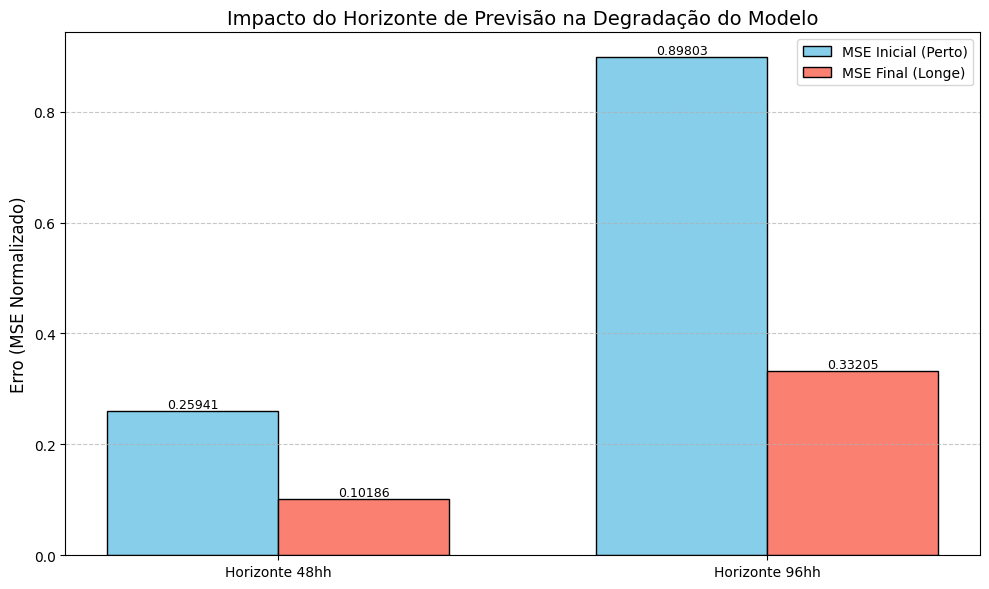

In [ ]:
horizontes = dfResultado.iloc[4:6]['Horizonte'].values
mse_inicial = dfResultado.iloc[4:6]['MSE_Inicial'].values
mse_final = dfResultado.iloc[4:6]['MSE_Final'].values

x = np.arange(len(horizontes))  # Localização dos grupos no eixo X
width = 0.35  # Largura das barras

plt.figure(figsize=(10, 6))
plt.bar(x - width/2, mse_inicial, width, label='MSE Inicial (Perto)', color='skyblue', edgecolor='black')
plt.bar(x + width/2, mse_final, width, label='MSE Final (Longe)', color='salmon', edgecolor='black')

# customização do Gráfico
plt.ylabel('Erro (MSE Normalizado)', fontsize=12)
plt.title('Impacto do Horizonte de Previsão na Degradação do Modelo', fontsize=14)
plt.xticks(x, [f'Horizonte {h}h' for h in horizontes])
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# adicionar os valores numéricos em cima das barras
for i in range(len(horizontes)):
    plt.text(i - width/2, mse_inicial[i], f'{mse_inicial[i]:.5f}', ha='center', va='bottom', fontsize=9)
    plt.text(i + width/2, mse_final[i], f'{mse_final[i]:.5f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

**Quarto DataSet:**

Quantidade de pedestres em Melbourne

In [ ]:
data,metadata = load_forecastingdata("pedestrian_counts_dataset")

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

pedestrian_counts_dataset/pedestrian_cou(…):   0%|          | 0.00/11.9M [00:00<?, ?B/s]

In [ ]:
dfFinal = formataDataSet(data)

Série T1 com 84331 horas,
Começando em 2009-05-01 00:00:01
            timestamp    T1
0 2009-05-01 00:00:01  53.0
0 2009-05-01 01:00:01  43.0
0 2009-05-01 02:00:01  10.0
0 2009-05-01 03:00:01   5.0
0 2009-05-01 04:00:01  25.0


In [ ]:
context_length = 512
# horizonte de previsão
fh = 48

# período de treinamento 0 - 600
y_treino = dfFinal.iloc[0:600]
# teste logo após o treino
y_teste = dfFinal.iloc[0:650]
# última hora 84331, período de contexto 84331 - 560 = 83771
y_testedistante = dfFinal.iloc[83771:84331]

# normalização
tsp = TimeSeriesPreprocessor(
    timestamp_column='timestamp',
    target_columns=['T1'],
    scaling=True,
)
# arrumar a escala
tsp.train(y_treino)


train_aug = tsp.preprocess(y_treino)
near_aug = tsp.preprocess(y_teste)
far_aug = tsp.preprocess(y_testedistante)

In [ ]:
# modelo escolhido PatchTSMixer
config = PatchTSMixerConfig(
    context_length=context_length,
    prediction_length=fh,
    num_input_channels=1,
    patch_length=8,
    d_model=16,
    num_layers=3,
    dropout=0.2,
    mode="common_channel",
    scaling="std",
)
model = PatchTSMixerForPrediction(config=config)

# configurando treinamento
train_args = TrainingArguments(
    output_dir="./checkpoint_univariado",
    num_train_epochs=30,
    per_device_train_batch_size=32,
    learning_rate=1e-3,
    save_strategy="no",
    logging_steps=10,
    report_to="none"
)

# separando datasets prontos do Toolkit
train_dataset = ForecastDFDataset(train_aug, target_columns=['T1'], context_length=context_length, prediction_length=fh)
trainer = Trainer(model=model, args=train_args, train_dataset=train_dataset)
trainer.train()


Step,Training Loss
10,0.354900
20,0.118600
30,0.093100
40,0.072100
50,0.064800
60,0.063000


TrainOutput(global_step=60, training_loss=0.12777321835358937, metrics={'train_runtime': 0.902, 'train_samples_per_second': 1363.581, 'train_steps_per_second': 66.516, 'total_flos': 437466562560.0, 'train_loss': 0.12777321835358937, 'epoch': 30.0})

In [ ]:
# organizando datasets de teste
dsTeste = ForecastDFDataset(near_aug, target_columns=['T1'], context_length=context_length, prediction_length=fh)
dsTesteMaisDistante = ForecastDFDataset(far_aug, target_columns=['T1'], context_length=context_length, prediction_length=fh)

# avaliando o erro (já da o mse)
metrics_near = trainer.evaluate(dsTeste)
metrics_far = trainer.evaluate(dsTesteMaisDistante)

# eval_loss nesse modelo é o mse
mse_base = metrics_near['eval_loss']
mse_degrad = metrics_far['eval_loss']

print(f'MSE INICIAL: {mse_base:.5f}')
print(f'MSE FINAL: {mse_degrad:.5f}')

if mse_degrad > mse_base:
    # Cálculo do aumento percentual do erro
    diff = ((mse_degrad - mse_base) / mse_base) * 100
    print(f'O erro aumentou {diff:.2f}% (Houve Degradação Temporal)')

elif mse_degrad < mse_base:
    # Caso raro onde o modelo performa melhor no futuro
    diff = ((mse_base - mse_degrad) / mse_base) * 100
    print(f'O erro diminuiu {diff:.2f}% (Não houve degradação)')
else:
    print('O modelo manteve a precisão no período.')

# salvando resultados para comparações futuras
resultado_atual = {
    'Dataset': 'Pedestres',
    'Horizonte': f'48h',
    'Contexto': context_length,
    'MSE_Inicial': mse_base,
    'MSE_Final': mse_degrad,
    'Degradacao_%': diff if mse_degrad > mse_base else 0
}
resultados.append(resultado_atual)

MSE INICIAL: 0.08355
MSE FINAL: 0.00369
O erro diminuiu 95.58% (Não houve degradação)


Aumentando o horizonte de previsão

In [ ]:
context_length = 512
# horizonte de previsão
fh = 96

# treino
y_treino = dfFinal.iloc[0:620]
y_teste = dfFinal.iloc[0:716]
# última hora
y_testedistante = dfFinal.iloc[83723:84331]

# normalização
tsp = TimeSeriesPreprocessor(
    timestamp_column='timestamp',
    target_columns=['T1'],
    scaling=True,
)
# arrumar a escala
tsp.train(y_treino)


train_aug = tsp.preprocess(y_treino)
near_aug = tsp.preprocess(y_teste)
far_aug = tsp.preprocess(y_testedistante)

In [ ]:
# modelo escolhido PatchTSMixer
config = PatchTSMixerConfig(
    context_length=context_length,
    prediction_length=fh,
    num_input_channels=1,
    patch_length=8,
    d_model=16,
    num_layers=3,
    dropout=0.2,
    mode="common_channel",
    scaling="std",
)
model = PatchTSMixerForPrediction(config=config)

# configurando treinamento
train_args = TrainingArguments(
    output_dir="./checkpoint_univariado",
    num_train_epochs=30,
    per_device_train_batch_size=32,
    learning_rate=1e-3,
    save_strategy="no",
    logging_steps=10,
    report_to="none"
)

# separando datasets prontos do Toolkit
train_dataset = ForecastDFDataset(train_aug, target_columns=['T1'], context_length=context_length, prediction_length=fh)
trainer = Trainer(model=model, args=train_args, train_dataset=train_dataset)
trainer.train()

Step,Training Loss
10,0.322500
20,0.086800
30,0.061000


TrainOutput(global_step=30, training_loss=0.15677528580029806, metrics={'train_runtime': 0.4516, 'train_samples_per_second': 863.614, 'train_steps_per_second': 66.432, 'total_flos': 197654446080.0, 'train_loss': 0.15677528580029806, 'epoch': 30.0})

In [ ]:
# organizando datasets de teste
dsTeste = ForecastDFDataset(near_aug, target_columns=['T1'], context_length=context_length, prediction_length=fh)
dsTesteMaisDistante = ForecastDFDataset(far_aug, target_columns=['T1'], context_length=context_length, prediction_length=fh)

# avaliando o erro (já da o mse)
metrics_near = trainer.evaluate(dsTeste)
metrics_far = trainer.evaluate(dsTesteMaisDistante)

# eval_loss nesse modelo é o mse
mse_base = metrics_near['eval_loss']
mse_degrad = metrics_far['eval_loss']

print(f'MSE INICIAL: {mse_base:.5f}')
print(f'MSE FINAL: {mse_degrad:.5f}')

if mse_degrad > mse_base:
    # Cálculo do aumento percentual do erro
    diff = ((mse_degrad - mse_base) / mse_base) * 100
    print(f'O erro aumentou {diff:.2f}% (Houve Degradação Temporal)')

elif mse_degrad < mse_base:
    # Caso raro onde o modelo performa melhor no futuro
    diff = ((mse_base - mse_degrad) / mse_base) * 100
    print(f'O erro diminuiu {diff:.2f}% (Não houve degradação)')
else:
    print('O modelo manteve a precisão no período.')

# salvando resultados para comparações futuras
resultado_atual = {
    'Dataset': 'Pedestres',
    'Horizonte': f'96h',
    'Contexto': context_length,
    'MSE_Inicial': mse_base,
    'MSE_Final': mse_degrad,
    'Degradacao_%': diff if mse_degrad > mse_base else 0
}

resultados.append(resultado_atual)

MSE INICIAL: 0.25451
MSE FINAL: 0.01344
O erro diminuiu 94.72% (Não houve degradação)


Resultados

In [ ]:
dfResultado = pd.DataFrame(resultados)
print('Tabela comparativa:')
display(dfResultado.iloc[6:8])

Tabela comparativa:


,Dataset,Horizonte,Contexto,MSE_Inicial,MSE_Final,Degradacao_%
6,Pedestres,48h,512,0.083549,0.003695,0.0
7,Pedestres,96h,512,0.254508,0.013442,0.0


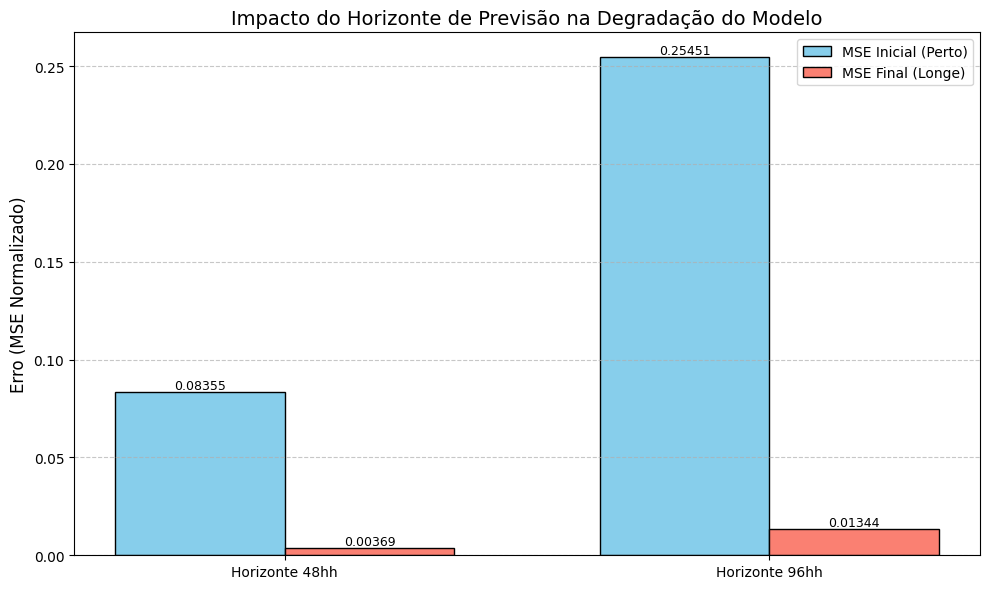

In [ ]:
horizontes = dfResultado.iloc[6:8]['Horizonte'].values
mse_inicial = dfResultado.iloc[6:8]['MSE_Inicial'].values
mse_final = dfResultado.iloc[6:8]['MSE_Final'].values

x = np.arange(len(horizontes))
width = 0.35

plt.figure(figsize=(10, 6))
plt.bar(x - width/2, mse_inicial, width, label='MSE Inicial (Perto)', color='skyblue', edgecolor='black')
plt.bar(x + width/2, mse_final, width, label='MSE Final (Longe)', color='salmon', edgecolor='black')

# customização do Gráfico
plt.ylabel('Erro (MSE Normalizado)', fontsize=12)
plt.title('Impacto do Horizonte de Previsão na Degradação do Modelo', fontsize=14)
plt.xticks(x, [f'Horizonte {h}h' for h in horizontes])
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# adicionando os valores numéricos em cima das barras
for i in range(len(horizontes)):
    plt.text(i - width/2, mse_inicial[i], f'{mse_inicial[i]:.5f}', ha='center', va='bottom', fontsize=9)
    plt.text(i + width/2, mse_final[i], f'{mse_final[i]:.5f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# Tabela final

In [ ]:
display(dfResultado)

,Dataset,Horizonte,Contexto,MSE_Inicial,MSE_Final,Degradacao_%
0,M4,48h,512,0.048053,0.035692,0.000000
1,M4,96,512,0.159036,0.231413,45.509497
2,Eletricidade,48h,512,0.168931,0.006963,0.000000
3,Eletricidade,96h,512,0.193221,0.042746,0.000000
4,Trafico,48h,512,0.259405,0.101863,0.000000
5,Trafico,96h,512,0.898031,0.332052,0.000000
6,Pedestres,48h,512,0.083549,0.003695,0.000000
7,Pedestres,96h,512,0.254508,0.013442,0.000000
